# 07. Recursive Multi-Step Forecasting (1–6 Hours)

**PondPredict: Philippine Bangus Pond pH and Water-Temperature Forecasting**

This notebook evaluates whether the **existing, selected** Philippine-only and transfer-learning LSTM checkpoints can produce reliable recursive forecasts beyond one hour. It **does not retrain, fine-tune, or overwrite** either checkpoint.

**Experimental design**
- Six observed hourly pH/temperature readings are the initial input.
- Predict one hour; append the **predicted pair** to the rolling window; remove the oldest input; repeat to six hours.
- Evaluate both models on **identical forecast origins**, using only the original 44-row Philippine held-out test partition.
- Hold 33 origins in common for **all horizons 1–6**, avoiding the unfair comparison of different origin counts at different horizons.
- Independently verify the original one-hour scores using **all 38** available one-hour test forecasts.
- Save forecasts, evaluation metrics, and manuscript-ready graphs to `results/recursive_multistep/`.

**Note:** Recursive forecasts are subject to compounding errors. Overlapping forecast origins are not independent samples. All horizon results describe this dataset, not guaranteed future performance in other ponds.

## 1. Imports and project paths
Run this notebook in the **same PondPredict virtual environment** as Notebooks 02–06. `KERAS_BACKEND` must be set **before** importing Keras. The notebook may live either in the project root or its `notebooks` directory.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import keras
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "PH_data.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "PH_data.csv"
SCALER_PATH = ROOT / "models" / "ph_scaler.pkl"
MODEL_PATHS = {
    "Philippine-only": ROOT / "models" / "ph_baseline.keras",
    "Transfer learning": ROOT / "models" / "transfer_final.keras",
}
OUT = ROOT / "results" / "recursive_multistep"
OUT.mkdir(parents=True, exist_ok=True)

for path in [DATA_PATH, SCALER_PATH, *MODEL_PATHS.values()]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}. Check your project root.")

SEQUENCE_LENGTH = 6
MAX_HORIZON = 6
SEED = 42
keras.utils.set_random_seed(SEED)

print("Project:", ROOT)
print("Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("Outputs:", OUT)
print("IMPORTANT: No training happens in this notebook.")

Project: C:\Users\Admin\Datas\PondPredict
Keras: 3.16.0.dev2026092704 | backend: torch
Outputs: C:\Users\Admin\Datas\PondPredict\results\recursive_multistep
IMPORTANT: No training happens in this notebook.


## 2. Load and verify the original Philippine held-out test split

Exactly match Notebook 02: sort timestamps, split all 288 observations chronologically using `int(total * .70)` and `int(total * .85)`, fit **no new scaler**, and take the final 44 observations as the test partition. No test targets are used for model fitting.

In [2]:
raw = pd.read_csv(DATA_PATH)
ph = raw.rename(columns={
    "Date & Time": "created_date",
    "pH": "water_pH",
    "Water Temp (°C)": "water_temp",
}).copy()

required = ["created_date", "water_pH", "water_temp"]
if not set(required).issubset(ph.columns):
    raise ValueError(f"Missing required columns. Found: {list(ph.columns)}")

ph["created_date"] = pd.to_datetime(ph["created_date"], format="%Y-%m-%d %H:%M")
ph = ph.sort_values("created_date").reset_index(drop=True)

if ph[required].isna().any().any():
    raise ValueError("Missing timestamps or readings detected; check the dataset.")
if ph["created_date"].duplicated().any():
    raise ValueError("Duplicate timestamps detected.")
if not ph["created_date"].diff().dropna().eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Data has a non-hourly gap; do not use this windowing procedure unchanged.")

N = len(ph)
TRAIN_END = int(N * 0.70)
VAL_END = int(N * 0.85)
train_df = ph.iloc[:TRAIN_END].copy()
val_df = ph.iloc[TRAIN_END:VAL_END].copy()
test_df = ph.iloc[VAL_END:].copy().reset_index(drop=True)

assert N == 288 and len(train_df) == 201 and len(val_df) == 43 and len(test_df) == 44, (
    "The uploaded PH dataset/split differs from the selected final experiment."
)

scaler = joblib.load(SCALER_PATH)
features = ["water_pH", "water_temp"]
test_scaled = np.asarray(scaler.transform(test_df[features]), dtype=np.float32)
test_original = test_df[features].to_numpy(dtype=float)

print("Total/train/val/test rows:", N, len(train_df), len(val_df), len(test_df))
print("Test range:", test_df.created_date.iloc[0], "to", test_df.created_date.iloc[-1])
print("One-hour origins:", len(test_df)-SEQUENCE_LENGTH)
print("Common origins for all 1–6 horizons:", len(test_df)-SEQUENCE_LENGTH-MAX_HORIZON+1)

Total/train/val/test rows: 288 201 43 44
Test range: 2026-10-02 04:00:00 to 2026-10-03 23:00:00
One-hour origins: 38
Common origins for all 1–6 horizons: 33


## 3. Load the two **final saved checkpoints** (no fitting)

Use `load_model` with `compile=False`. A compatibility fallback rebuilds the **known 6×2 → LSTM(16) → Dropout(0.20) → Dense(2)** architecture and loads the original `.keras` **weights**, only if your local Keras release cannot deserialize a checkpoint. This is not retraining. The next cell verifies one-hour accuracy to catch unexpected checkpoint or preprocessing mismatches.

In [3]:
def load_final_checkpoint(path, *, transfer):
    try:
        model = keras.models.load_model(path, compile=False)
        mode = "native Keras checkpoint"
    except (TypeError, ValueError) as exc:
        # Some Keras releases do not understand initializer fields in newer checkpoints.
        # Use exactly the same architecture and restore its saved weights instead.
        from keras import Sequential
        from keras.layers import Input, LSTM, Dropout, Dense
        names = (
            ["transfer_lstm", "transfer_dropout", "transfer_output"]
            if transfer else ["lstm", "dropout", "dense"]
        )
        model = Sequential([
            Input(shape=(SEQUENCE_LENGTH, 2)),
            LSTM(16, name=names[0]),
            Dropout(0.20, name=names[1]),
            Dense(2, name=names[2]),
        ])
        model.load_weights(path)
        mode = "reconstructed architecture + original checkpoint weights"
        warnings.warn(
            "Keras checkpoint deserialization differed across installed versions. "
            "Loaded exact saved weights into the documented architecture. "
            f"Original message: {str(exc)[:180]}",
            RuntimeWarning,
        )

    if tuple(model.input_shape[1:]) != (SEQUENCE_LENGTH, 2):
        raise AssertionError(f"Unexpected input shape for {path}: {model.input_shape}")
    if tuple(model.output_shape[1:]) != (2,):
        raise AssertionError(f"Unexpected output shape for {path}: {model.output_shape}")
    print(path.name, "=>", mode)
    return model

models = {
    label: load_final_checkpoint(path, transfer=(label == "Transfer learning"))
    for label, path in MODEL_PATHS.items()
}

ph_baseline.keras => native Keras checkpoint
transfer_final.keras => native Keras checkpoint


## 4. Verify the original 38 one-hour test predictions

This is a **checkpoint integrity check**, not the new six-hour result. MAE should reproduce the original final scores (pH around **0.02277 / 0.02298**, temperature around **0.18708 / 0.15818** for baseline / transfer). No automatic model retraining occurs if verification fails.

In [4]:
X_1h_all = np.stack([
    test_scaled[i:i+SEQUENCE_LENGTH]
    for i in range(len(test_scaled)-SEQUENCE_LENGTH)
]).astype(np.float32)
Y_1h_all = test_original[SEQUENCE_LENGTH:]
assert len(X_1h_all) == len(Y_1h_all) == 38

EXPECTED_MAE = {
    "Philippine-only": (0.0227735459, 0.1870752736),
    "Transfer learning": (0.0229779133, 0.1581814716),
}

verification = []
for name, model in models.items():
    pred_scaled = model.predict(X_1h_all, verbose=0)
    pred = scaler.inverse_transform(pred_scaled)
    for j, target in enumerate(["pH", "temperature"]):
        mae = float(mean_absolute_error(Y_1h_all[:, j], pred[:, j]))
        rmse = float(np.sqrt(mean_squared_error(Y_1h_all[:, j], pred[:, j])))
        r2 = float(r2_score(Y_1h_all[:, j], pred[:, j]))
        expected = EXPECTED_MAE[name][j]
        verification.append({
            "model": name, "target": target, "test_forecasts": 38,
            "MAE": mae, "RMSE": rmse, "R2": r2,
            "previously_reported_MAE": expected,
            "checkpoint_matches_reported_MAE": abs(mae-expected) < 0.0005,
        })

verification_df = pd.DataFrame(verification)
display(verification_df)
verification_df.to_csv(OUT / "recursive_one_hour_checkpoint_verification.csv", index=False)
if not verification_df.checkpoint_matches_reported_MAE.all():
    raise AssertionError(
        "At least one final model or scaler did not reproduce its published one-hour MAE. "
        "Do not report recursive metrics until resolved."
    )
print("PASS: Both final saved models reproduce the original 38-prediction MAE scores.")

,model,target,test_forecasts,MAE,RMSE,R2,previously_reported_MAE,checkpoint_matches_reported_MAE
0,Philippine-only,pH,38,0.022774,0.028628,0.810681,0.022774,True
1,Philippine-only,temperature,38,0.187075,0.231706,0.981441,0.187075,True
2,Transfer learning,pH,38,0.022978,0.028046,0.818299,0.022978,True
3,Transfer learning,temperature,38,0.158181,0.204537,0.985538,0.158181,True


PASS: Both final saved models reproduce the original 38-prediction MAE scores.


## 5. Recursive prediction from identical starting points

**No teacher forcing.** For each origin, the first input window contains only actual readings observed **up to that origin**. Subsequent windows append the previously predicted **scaled** pH and temperature, not the true next-hour observations.

For a fair horizon comparison, use the same 33 origins where all six future targets exist. This differs from the 38-origin one-hour verification above.

In [5]:
n_origins = len(test_scaled) - SEQUENCE_LENGTH - MAX_HORIZON + 1
assert n_origins == 33

initial_windows = np.stack([
    test_scaled[i:i + SEQUENCE_LENGTH]
    for i in range(n_origins)
]).astype(np.float32)
origin_timestamps = [
    test_df.created_date.iloc[i+SEQUENCE_LENGTH-1]
    for i in range(n_origins)
]

# [origin, forecast_horizon, variable]; all TRUE future values for scoring only
actual_cube = np.stack([
    test_original[i+SEQUENCE_LENGTH:i+SEQUENCE_LENGTH+MAX_HORIZON]
    for i in range(n_origins)
])
assert actual_cube.shape == (33, 6, 2)

prediction_cubes = {}
for model_name, model in models.items():
    rolling = initial_windows.copy()
    scaled_predictions = []
    for horizon in range(1, MAX_HORIZON+1):
        next_scaled = np.asarray(model.predict(rolling, verbose=0), dtype=np.float32)
        assert next_scaled.shape == (n_origins, 2)
        scaled_predictions.append(next_scaled)
        # Shift left and append PREDICTIONS for all next steps.
        rolling = np.concatenate([rolling[:, 1:, :], next_scaled[:, None, :]], axis=1)

    pred_cube_scaled = np.stack(scaled_predictions, axis=1)
    pred_cube = scaler.inverse_transform(pred_cube_scaled.reshape(-1, 2)).reshape(n_origins, MAX_HORIZON, 2)
    prediction_cubes[model_name] = pred_cube
    print(model_name, "recursive forecasts:", pred_cube.shape)

print("PASS: All horizons use the same 33 initial windows, with fully recursive inputs.")

Philippine-only recursive forecasts: (33, 6, 2)
Transfer learning recursive forecasts: (33, 6, 2)
PASS: All horizons use the same 33 initial windows, with fully recursive inputs.


## 6. Export timestamped individual recursive forecasts

One row per model × origin × horizon. Each row contains the origin time, target time, actual/predicted values for **both** variables, and their absolute errors. The actual future values are used **only for evaluation after forecasting**.

In [6]:
forecast_rows = []
for model_name, pred_cube in prediction_cubes.items():
    for i in range(n_origins):
        for j in range(MAX_HORIZON):
            h = j+1
            forecast_rows.append({
                "model": model_name,
                "forecast_origin": origin_timestamps[i],
                "forecast_timestamp": test_df.created_date.iloc[i+SEQUENCE_LENGTH+j],
                "horizon_hours": h,
                "actual_pH": actual_cube[i,j,0],
                "predicted_pH": pred_cube[i,j,0],
                "absolute_error_pH": abs(actual_cube[i,j,0]-pred_cube[i,j,0]),
                "actual_temperature_C": actual_cube[i,j,1],
                "predicted_temperature_C": pred_cube[i,j,1],
                "absolute_error_temperature_C": abs(actual_cube[i,j,1]-pred_cube[i,j,1]),
            })

forecasts_df = pd.DataFrame(forecast_rows)
assert len(forecasts_df) == 2*33*6
assert forecasts_df.notna().all().all()
assert (
    forecasts_df.forecast_timestamp - forecasts_df.forecast_origin
    == pd.to_timedelta(forecasts_df.horizon_hours, unit="h")
).all()
forecasts_df.to_csv(OUT / "recursive_multistep_forecasts.csv", index=False)
print("Saved", len(forecasts_df), "timestamped model forecasts.")
display(forecasts_df.head(8))

Saved 396 timestamped model forecasts.


,model,forecast_origin,forecast_timestamp,horizon_hours,actual_pH,predicted_pH,absolute_error_pH,actual_temperature_C,predicted_temperature_C,absolute_error_temperature_C
0,Philippine-only,2026-10-02 09:00:00,2026-10-02 10:00:00,1,7.67,7.677261,0.007261,30.3,30.032307,0.267693
1,Philippine-only,2026-10-02 09:00:00,2026-10-02 11:00:00,2,7.69,7.703666,0.013666,30.9,30.493122,0.406878
2,Philippine-only,2026-10-02 09:00:00,2026-10-02 12:00:00,3,7.72,7.728364,0.008364,31.5,30.933655,0.566345
3,Philippine-only,2026-10-02 09:00:00,2026-10-02 13:00:00,4,7.74,7.750436,0.010436,32.1,31.326126,0.773874
4,Philippine-only,2026-10-02 09:00:00,2026-10-02 14:00:00,5,7.75,7.768857,0.018857,32.5,31.637602,0.862398
5,Philippine-only,2026-10-02 09:00:00,2026-10-02 15:00:00,6,7.76,7.782047,0.022047,32.7,31.837318,0.862682
6,Philippine-only,2026-10-02 10:00:00,2026-10-02 11:00:00,1,7.69,7.709100,0.019100,30.9,30.673464,0.226536
7,Philippine-only,2026-10-02 10:00:00,2026-10-02 12:00:00,2,7.72,7.735594,0.015594,31.5,31.150747,0.349253


## 7. Evaluate MAE, RMSE, and R² at each horizon

Thirty-three paired forecast origins per horizon. A comparison at a fixed horizon uses identical actual target timestamps for both models. Interpret R² cautiously if test-period variability is small; it can be negative for poor multi-step predictions.

In [7]:
metrics_rows = []
for model_name, pred_cube in prediction_cubes.items():
    for j in range(MAX_HORIZON):
        for k, target in enumerate(["pH", "temperature"]):
            y_true = actual_cube[:, j, k]
            y_pred = pred_cube[:, j, k]
            metrics_rows.append({
                "model": model_name,
                "target": target,
                "horizon_hours": j+1,
                "forecast_origins": n_origins,
                "MAE": float(mean_absolute_error(y_true, y_pred)),
                "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
                "R2": float(r2_score(y_true, y_pred)),
            })

metrics_df = pd.DataFrame(metrics_rows)
assert len(metrics_df) == 2*2*6
metrics_df.to_csv(OUT / "recursive_multistep_metrics.csv", index=False)
print("Saved detailed metrics for every horizon (1–6 hours).")
display(metrics_df.round(5))

# Chapter 4 summary with both target metrics side by side
selected = metrics_df[metrics_df.horizon_hours.isin([1,3,6])]
summary_rows = []
for (name,h),g in selected.groupby(["model","horizon_hours"],sort=False):
    p = g.set_index("target")
    summary_rows.append({
        "model": name, "horizon_hours": h, "forecast_origins": n_origins,
        "pH_MAE": p.loc["pH", "MAE"], "pH_RMSE": p.loc["pH", "RMSE"],
        "pH_R2": p.loc["pH", "R2"],
        "temperature_MAE_C": p.loc["temperature", "MAE"],
        "temperature_RMSE_C": p.loc["temperature", "RMSE"],
        "temperature_R2": p.loc["temperature", "R2"],
    })
summary_df = pd.DataFrame(summary_rows).sort_values(["model", "horizon_hours"])
summary_df.to_csv(OUT / "recursive_multistep_chapter4_table.csv", index=False)
print("\nSECTION 4.9 REPORTING TABLE, SAME 33 ORIGINS FOR ALL HORIZONS:")
display(summary_df.round(5))

Saved detailed metrics for every horizon (1–6 hours).


,model,target,horizon_hours,forecast_origins,MAE,RMSE,R2
0,Philippine-only,pH,1,33,0.02306,0.02954,0.80860
1,Philippine-only,temperature,1,33,0.20400,0.24613,0.98069
2,Philippine-only,pH,2,33,0.02784,0.03492,0.74555
3,Philippine-only,temperature,2,33,0.33371,0.39751,0.95015
4,Philippine-only,pH,3,33,0.03223,0.03956,0.68054
5,Philippine-only,temperature,3,33,0.46303,0.55391,0.90328
6,Philippine-only,pH,4,33,0.03483,0.04241,0.63381
7,Philippine-only,temperature,4,33,0.59001,0.69783,0.84648
8,Philippine-only,pH,5,33,0.03592,0.04305,0.61915
9,Philippine-only,temperature,5,33,0.68563,0.81894,0.78898



SECTION 4.9 REPORTING TABLE, SAME 33 ORIGINS FOR ALL HORIZONS:


,model,horizon_hours,forecast_origins,pH_MAE,pH_RMSE,pH_R2,temperature_MAE_C,temperature_RMSE_C,temperature_R2
0,Philippine-only,1,33,0.02306,0.02954,0.80860,0.20400,0.24613,0.98069
1,Philippine-only,3,33,0.03223,0.03956,0.68054,0.46303,0.55391,0.90328
2,Philippine-only,6,33,0.03560,0.04270,0.62124,0.75683,0.90463,0.74260
3,Transfer learning,1,33,0.02515,0.02990,0.80380,0.17186,0.21686,0.98501
4,Transfer learning,3,33,0.03525,0.04107,0.65555,0.51257,0.57967,0.89408
5,Transfer learning,6,33,0.03355,0.04060,0.65762,0.90950,1.02974,0.66649


## 8. Compare errors between the two models at each forecast horizon

Compute relative MAE differences (positive means transfer learning has lower MAE), but **do not** claim statistical significance from these descriptive differences. The same origins overlap strongly across horizons.

In [8]:
comparison_rows = []
for target in ["pH", "temperature"]:
    for h in range(1, MAX_HORIZON+1):
        current = metrics_df[(metrics_df.target == target)&(metrics_df.horizon_hours == h)]
        base_mae = float(current.loc[current.model == "Philippine-only", "MAE"].iloc[0])
        tl_mae = float(current.loc[current.model == "Transfer learning", "MAE"].iloc[0])
        comparison_rows.append({
            "target": target, "horizon_hours": h,
            "baseline_MAE": base_mae, "transfer_MAE": tl_mae,
            "transfer_MAE_reduction_percent": 100*(base_mae-tl_mae)/base_mae,
            "lower_MAE_model": "Transfer learning" if tl_mae < base_mae else (
                "Philippine-only" if base_mae < tl_mae else "Equal"
            ),
        })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(OUT / "recursive_multistep_model_comparison.csv", index=False)
display(comparison_df.round(4))

,target,horizon_hours,baseline_MAE,transfer_MAE,transfer_MAE_reduction_percent,lower_MAE_model
0,pH,1,0.0231,0.0252,-9.0859,Philippine-only
1,pH,2,0.0278,0.0308,-10.4970,Philippine-only
2,pH,3,0.0322,0.0353,-9.3875,Philippine-only
3,pH,4,0.0348,0.0366,-5.0225,Philippine-only
4,pH,5,0.0359,0.0361,-0.3794,Philippine-only
5,pH,6,0.0356,0.0336,5.7446,Transfer learning
6,temperature,1,0.2040,0.1719,15.7568,Transfer learning
7,temperature,2,0.3337,0.3346,-0.2509,Philippine-only
8,temperature,3,0.4630,0.5126,-10.6977,Philippine-only
9,temperature,4,0.5900,0.6828,-15.7315,Philippine-only


## 9. Produce the Chapter 4 MAE-versus-horizon figures

The x-axis includes **every horizon 1–6**; the manuscript table highlights 1, 3, and 6 hours. Both model curves use identical 33 origins per horizon.

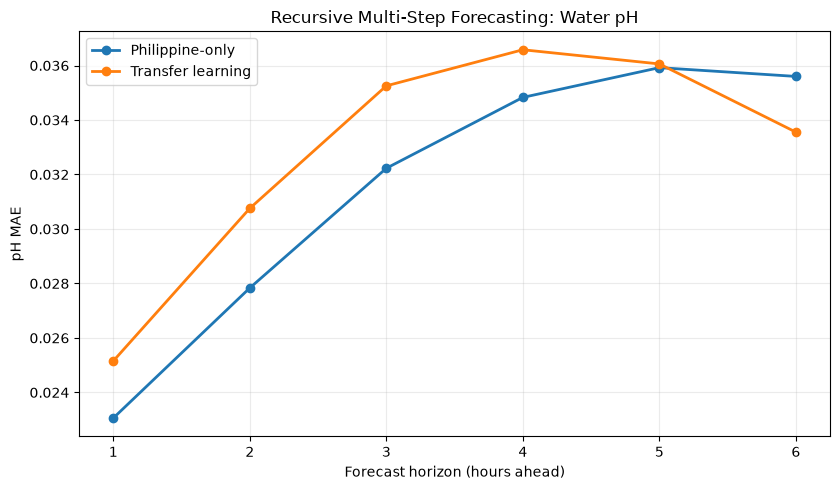

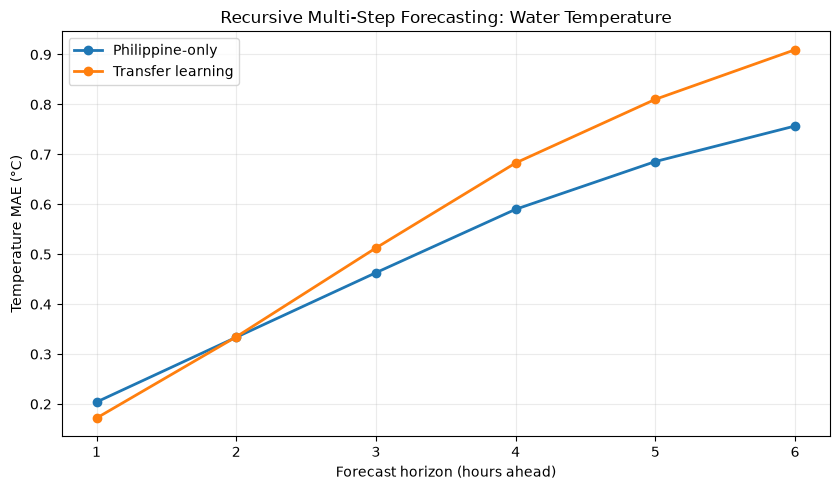

Saved MAE-by-horizon graphs: {'pH': 'recursive_ph_mae_by_horizon.png', 'temperature': 'recursive_temperature_mae_by_horizon.png'}


In [9]:
figure_files = {}
for target, ylabel, filename in [
    ("pH", "pH MAE", "recursive_ph_mae_by_horizon.png"),
    ("temperature", "Temperature MAE (°C)", "recursive_temperature_mae_by_horizon.png"),
]:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    for name in MODEL_PATHS:
        g = metrics_df[(metrics_df.model == name) & (metrics_df.target == target)].sort_values("horizon_hours")
        ax.plot(g.horizon_hours, g.MAE, marker="o", linewidth=2, label=name)
    ax.set_xticks(range(1,MAX_HORIZON+1))
    ax.set_xlabel("Forecast horizon (hours ahead)")
    ax.set_ylabel(ylabel)
    ax.set_title("Recursive Multi-Step Forecasting: " + ("Water pH" if target == "pH" else "Water Temperature"))
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT/filename, dpi=220, bbox_inches="tight")
    figure_files[target] = filename
    plt.show()
    plt.close(fig)
print("Saved MAE-by-horizon graphs:", figure_files)

## 10. Show an example six-hour forecast trajectory

Illustrative trajectory from the **first eligible held-out origin**, not a separate evaluation dataset. This plot helps explain recursion to the adviser. Numerical performance claims must come from the full 33-origin evaluation, not this one example.

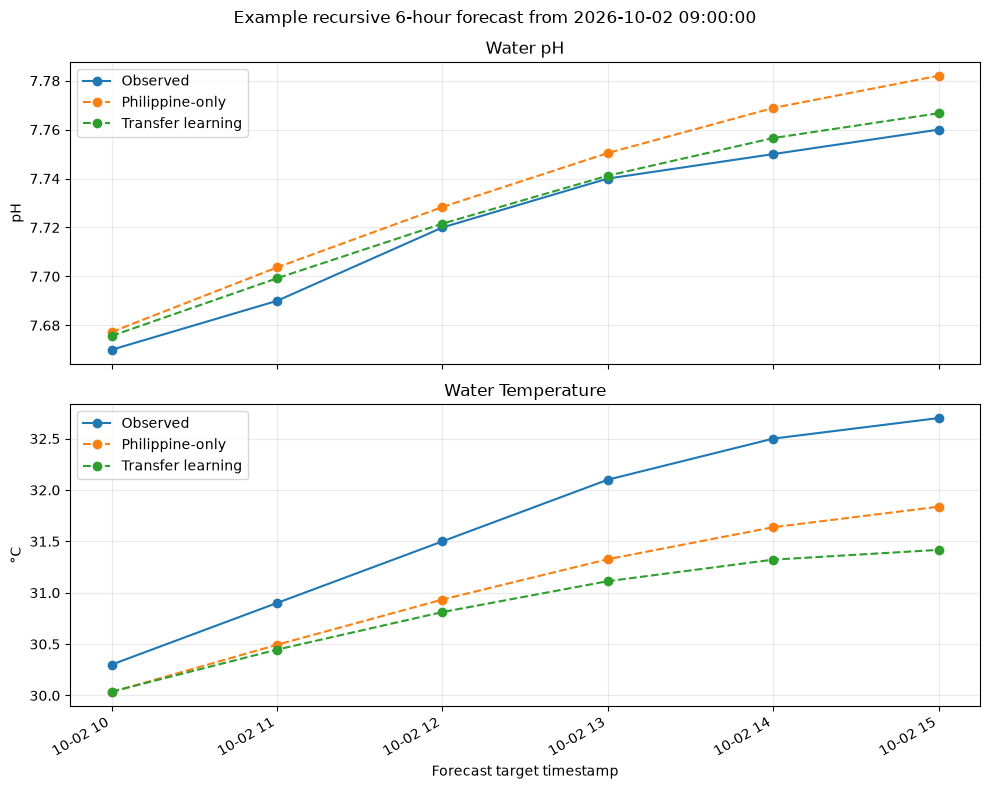

Illustrative example saved.


In [10]:
example_origin = 0
future_dates = [
    test_df.created_date.iloc[example_origin+SEQUENCE_LENGTH+j]
    for j in range(MAX_HORIZON)
]
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for k, (ax, label, unit) in enumerate(zip(axes,["Water pH","Water Temperature"],["pH","°C"])):
    ax.plot(future_dates, actual_cube[example_origin,:,k], "o-", label="Observed")
    for name, pred_cube in prediction_cubes.items():
        ax.plot(future_dates, pred_cube[example_origin,:,k], "o--", label=name)
    ax.set_ylabel(unit)
    ax.set_title(label)
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].set_xlabel("Forecast target timestamp")
fig.suptitle(f"Example recursive 6-hour forecast from {origin_timestamps[example_origin]}")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT/"recursive_example_6_hour_trajectory.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Illustrative example saved.")

## 11. Final integrity summary

All saved numerical results are from **the existing checkpoints**, no retraining. Use `recursive_multistep_chapter4_table.csv` and `recursive_ph_mae_by_horizon.png` / `recursive_temperature_mae_by_horizon.png` for the new Chapter 4 Section 4.9. Rename the existing Overall Discussion to Section 4.10 and add a short description of recursive evaluation to Chapter 3.

In [11]:
assert len(verification_df) == 4 and verification_df.checkpoint_matches_reported_MAE.all()
assert len(forecasts_df) == 396
assert len(metrics_df) == 24 and metrics_df.forecast_origins.eq(33).all()
assert len(summary_df) == 6
assert set(metrics_df.horizon_hours) == set(range(1,7))
assert all((OUT / f).is_file() for f in [
    "recursive_one_hour_checkpoint_verification.csv",
    "recursive_multistep_forecasts.csv",
    "recursive_multistep_metrics.csv",
    "recursive_multistep_chapter4_table.csv",
    "recursive_multistep_model_comparison.csv",
    "recursive_ph_mae_by_horizon.png",
    "recursive_temperature_mae_by_horizon.png",
    "recursive_example_6_hour_trajectory.png",
])

print("VERIFIED: Original 38 one-hour forecasts matched.")
print("VERIFIED: Same 33 eligible forecast origins for both models and all six horizons.")
print("VERIFIED: Recursive predictions generated only from observed past + prior predictions.")
print("VERIFIED: All CSVs and figures exported to:", OUT)
print("IMPORTANT: These are new hold-out multi-step results, not replacements for original one-hour figures.")

VERIFIED: Original 38 one-hour forecasts matched.
VERIFIED: Same 33 eligible forecast origins for both models and all six horizons.
VERIFIED: Recursive predictions generated only from observed past + prior predictions.
VERIFIED: All CSVs and figures exported to: C:\Users\Admin\Datas\PondPredict\results\recursive_multistep
IMPORTANT: These are new hold-out multi-step results, not replacements for original one-hour figures.
